Estadístico Chi-cuadrado: 1046.04
P-valor: 1.7633e-229
V de Cramér: 0.3285


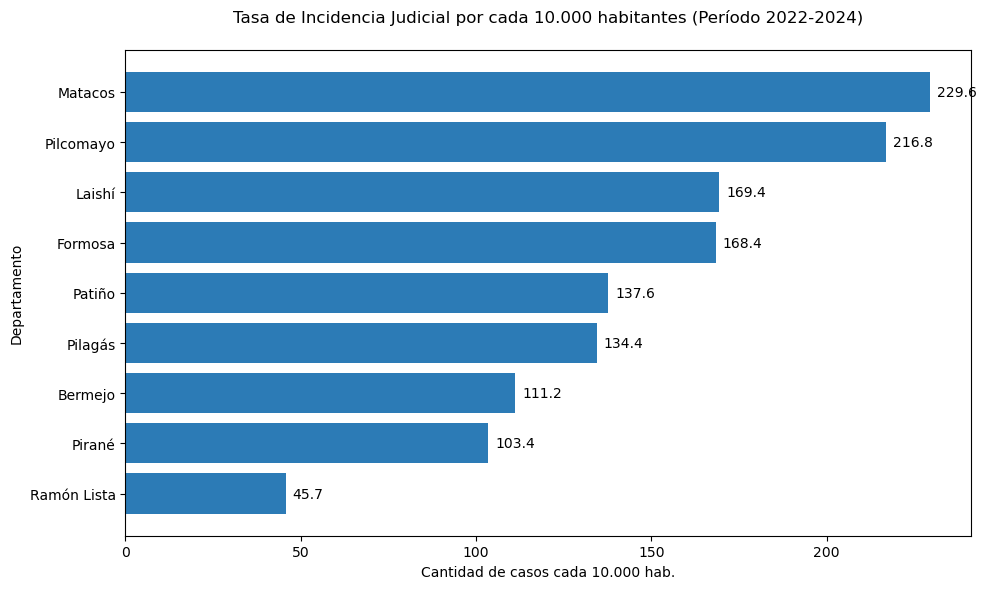

<Figure size 640x480 with 0 Axes>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# =========================================================
# 1. PRUEBA DE CHI-CUADRADO Y V DE CRAMÉR
# =========================================================
# Matriz de contingencia: Violencia Física vs Prohibición de acercamiento
obs = np.array([[3563, 2704],   # Sin violencia física
                [777, 2651]])   # Con violencia física

chi2, p, dof, expected = chi2_contingency(obs)

# Cálculo de V de Cramér
n = obs.sum()
min_dim = min(obs.shape) - 1
v = np.sqrt(chi2 / (n * min_dim))

print(f"Estadístico Chi-cuadrado: {chi2:.2f}")
print(f"P-valor: {p:.4e}")
print(f"V de Cramér: {v:.4f}")

# =========================================================
# 2. TASA DE INCIDENCIA TERRITORIAL (CENSO 2022)
# =========================================================
data = {
    'Departamento': ['Formosa', 'Pilcomayo', 'Patiño', 'Pirané', 'Matacos', 'Laishí', 'Pilagás', 'Bermejo', 'Ramón Lista'],
    'Poblacion_2022': [269589, 94383, 81819, 72804, 17032, 19303, 19116, 15644, 17729],
    'Casos_Totales': [4539, 2046, 1126, 753, 391, 327, 257, 174, 81]
}

df_dep = pd.DataFrame(data)
# Cálculo de tasa cada 10.000 habitantes
df_dep['Tasa_cada_10k'] = (df_dep['Casos_Totales'] / df_dep['Poblacion_2022']) * 10000
df_dep = df_dep.sort_values(by='Tasa_cada_10k', ascending=True) # Ordenado para el gráfico

# =========================================================
# 3. GRÁFICO DE TASA DE INCIDENCIA
# =========================================================
plt.figure(figsize=(10, 6))
bars = plt.barh(df_dep['Departamento'], df_dep['Tasa_cada_10k'], color='#2c7bb6')

plt.title('Tasa de Incidencia Judicial por cada 10.000 habitantes (Período 2022-2024)', pad=20)
plt.xlabel('Cantidad de casos cada 10.000 hab.')
plt.ylabel('Departamento')

# Agregar los valores al final de cada barra
for bar in bars:
    plt.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2, 
             f'{bar.get_width():.1f}', 
             va='center', ha='left', fontsize=10)

plt.tight_layout()
plt.show()

#Se guarda el grafico
plt.savefig('Figura_4_11b_Tasa_Incidencia.png', dpi=300, bbox_inches='tight')

plt.show()